# Thực hành: phân cụm hoa Iris bằng K-means

*Bài 8, mục 8.2.2.*

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

DATA = Path('..') / 'data'   # notebook chạy trong codes/
columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
df = pd.read_csv(DATA / 'iris.data', header=None, names=columns)
features = columns[:4]
X = df[features].to_numpy()
species = df['species'].to_numpy()          # chỉ dùng để đánh giá
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 1. Chọn số cụm K

K =  1: inertia =  600.00, silhouette = nan
K =  2: inertia =  222.36, silhouette = 0.582
K =  3: inertia =  139.82, silhouette = 0.460
K =  4: inertia =  114.09, silhouette = 0.387
K =  5: inertia =   90.93, silhouette = 0.346
K =  6: inertia =   81.54, silhouette = 0.317
K =  7: inertia =   72.63, silhouette = 0.320


K =  8: inertia =   62.54, silhouette = 0.339
K =  9: inertia =   55.12, silhouette = 0.342
K = 10: inertia =   47.39, silhouette = 0.352


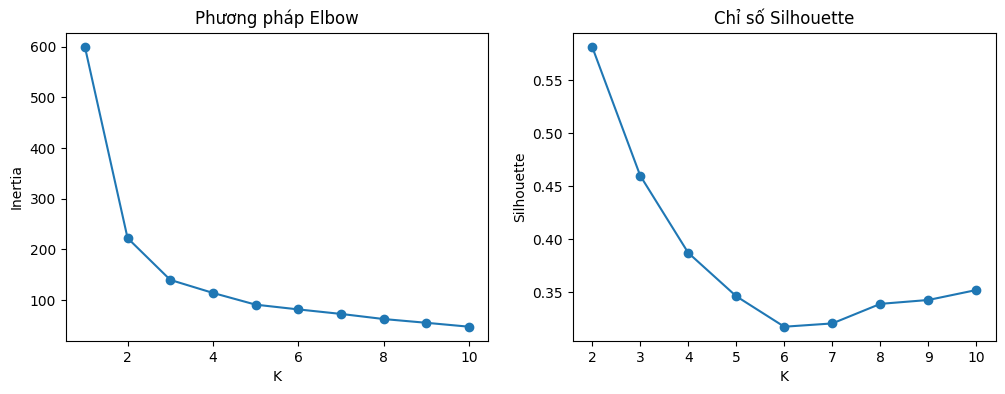

In [2]:
K_values = range(1, 11)
inertias, silhouettes = [], []
for k in K_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_scaled, model.labels_) if k > 1 else np.nan)
    print('K = %2d: inertia = %7.2f, silhouette = %.3f' % (k, inertias[-1], silhouettes[-1]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(K_values, inertias, 'o-'); axes[0].set_xlabel('K'); axes[0].set_ylabel('Inertia')
axes[0].set_title('Phương pháp Elbow')
axes[1].plot(K_values, silhouettes, 'o-'); axes[1].set_xlabel('K'); axes[1].set_ylabel('Silhouette')
axes[1].set_title('Chỉ số Silhouette')
plt.show()

Silhouette lớn nhất tại $K = 2$: setosa tách hẳn, còn versicolor và virginica chồng lấn nên về mặt hình học trông như một cụm. Đồ thị Elbow có khuỷu tay ở khoảng $K = 2$ – $3$. Biết trước có 3 loài, ta chọn $K = 3$: lựa chọn $K$ trong thực tế kết hợp chỉ số định lượng với hiểu biết về bài toán.

## 2. Phân cụm với K = 3

In [3]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
labels = kmeans.fit_predict(X_scaled)
print('Số điểm mỗi cụm:', np.bincount(labels))
print('Inertia: %.2f, silhouette: %.3f' % (kmeans.inertia_, silhouette_score(X_scaled, labels)))

Số điểm mỗi cụm: [53 50 47]
Inertia: 139.82, silhouette: 0.460


Tâm cụm trên thang chuẩn hóa khó đọc; đổi về đơn vị cm bằng `inverse_transform`:

In [4]:
centers_cm = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=features)
centers_cm.round(2)

,sepal_length,sepal_width,petal_length,petal_width
0,5.80,2.67,4.37,1.41
1,5.01,3.43,1.46,0.25
2,6.78,3.10,5.51,1.97


## 3. Đánh giá bằng nhãn thật

Số thứ tự cụm do K-means đặt là tùy ý (cụm 0 không nhất thiết là setosa). Bảng chéo cho biết mỗi cụm chứa bao nhiêu hoa của mỗi loài.

In [5]:
pd.crosstab(species, labels, rownames=['Loài'], colnames=['Cụm'])

Cụm,0,1,2
Loài,,,
Iris-setosa,0,50,0
Iris-versicolor,39,0,11
Iris-virginica,14,0,36


Gán mỗi cụm với loài chiếm đa số để tính tỉ lệ khớp, và tính **Adjusted Rand Index** (ARI): 1 là khớp hoàn toàn, khoảng 0 là ngẫu nhiên; ARI không phụ thuộc cách đánh số cụm.

In [6]:
from sklearn.metrics import adjusted_rand_score

mapping = pd.crosstab(labels, species).idxmax(axis=1)     # cụm -> loài đa số
predicted_species = mapping[labels].to_numpy()
print('Ánh xạ cụm -> loài:', mapping.to_dict())
print('Tỉ lệ khớp với loài thật: %.3f' % (predicted_species == species).mean())
print('Adjusted Rand Index: %.3f' % adjusted_rand_score(species, labels))

Ánh xạ cụm -> loài: {0: 'Iris-versicolor', 1: 'Iris-setosa', 2: 'Iris-virginica'}
Tỉ lệ khớp với loài thật: 0.833
Adjusted Rand Index: 0.620


## 4. Trực quan hóa

Dữ liệu có 4 chiều. Vẽ trên hai đặc trưng cánh hoa, hoặc chiếu xuống 2 chiều bằng PCA (phân tích thành phần chính, một kỹ thuật học không giám sát giảm số chiều).

Tỉ lệ phương sai giữ lại: 0.958


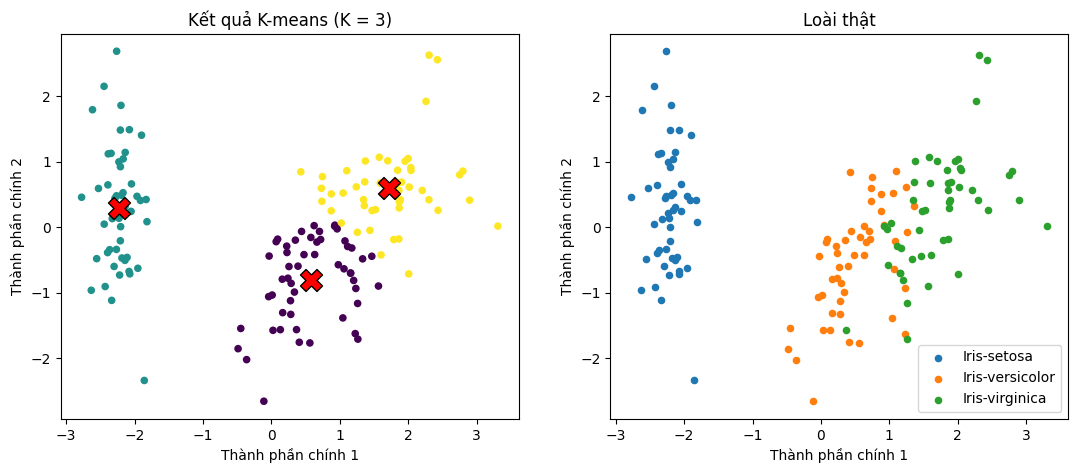

In [7]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2).fit(X_scaled)
X_2d = pca.transform(X_scaled)
centers_2d = pca.transform(kmeans.cluster_centers_)
print('Tỉ lệ phương sai giữ lại: %.3f' % pca.explained_variance_ratio_.sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap='viridis', s=20)
axes[0].scatter(*centers_2d.T, marker='X', s=250, c='red', edgecolors='k')
axes[0].set_title('Kết quả K-means (K = 3)')
for name in np.unique(species):
    axes[1].scatter(X_2d[species == name, 0], X_2d[species == name, 1], s=20, label=name)
axes[1].set_title('Loài thật'); axes[1].legend()
for ax in axes:
    ax.set_xlabel('Thành phần chính 1'); ax.set_ylabel('Thành phần chính 2')
plt.show()

## 5. Ảnh hưởng của chuẩn hóa

In [8]:
for name, data in [('Chưa chuẩn hóa', X), ('Đã chuẩn hóa', X_scaled)]:
    labels_k = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(data)
    print('%-15s ARI = %.3f' % (name, adjusted_rand_score(species, labels_k)))

Chưa chuẩn hóa  ARI = 0.730
Đã chuẩn hóa    ARI = 0.620


Với Iris, dữ liệu chưa chuẩn hóa lại cho kết quả khớp nhãn tốt hơn: `petal_length` có phương sai lớn nhất và cũng là đặc trưng phân biệt loài tốt nhất, nên việc nó "chi phối" khoảng cách lại có lợi. Chuẩn hóa là mặc định an toàn khi các đặc trưng khác đơn vị, nhưng không phải lúc nào cũng cho kết quả tốt hơn; cần thử và đánh giá.

## 6. So sánh với phân cụm phân cấp

ward     linkage: ARI = 0.615, số điểm mỗi cụm [71 49 30]
complete linkage: ARI = 0.573, số điểm mỗi cụm [77 49 24]
average  linkage: ARI = 0.562, số điểm mỗi cụm [50 97  3]
single   linkage: ARI = 0.558, số điểm mỗi cụm [100   1  49]


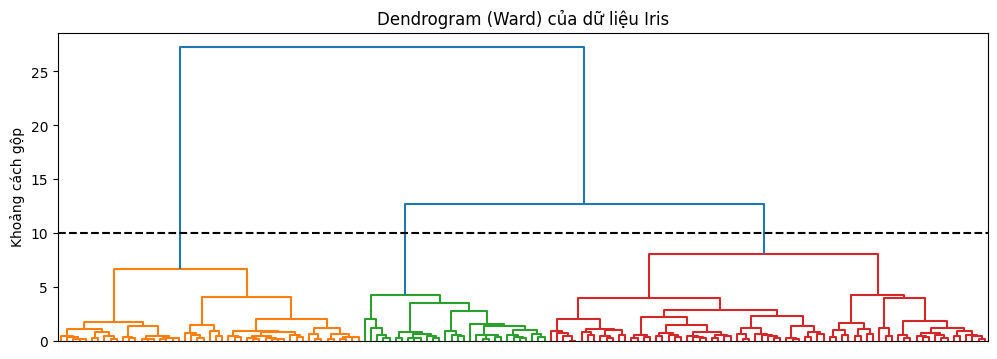

In [9]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

for method in ['ward', 'complete', 'average', 'single']:
    labels_h = AgglomerativeClustering(n_clusters=3, linkage=method).fit_predict(X_scaled)
    print('%-8s linkage: ARI = %.3f, số điểm mỗi cụm %s' % (method, adjusted_rand_score(species, labels_h), np.bincount(labels_h)))

plt.figure(figsize=(12, 4))
dendrogram(linkage(X_scaled, method='ward'), no_labels=True, color_threshold=10)
plt.axhline(10, color='k', ls='--')
plt.title('Dendrogram (Ward) của dữ liệu Iris'); plt.ylabel('Khoảng cách gộp')
plt.show()